# Housing affordability in the 50 largest US metros

How much of a typical household's income does a typical home cost, and how has that changed since 2021?

**Data:** Zillow Home Value Index and Observed Rent Index (monthly), Census ACS 1-year median household income (2021 onward), Freddie Mac 30-year fixed mortgage rate. Rebuild with `python scripts/build_data.py`.

**Measures** (see `src/housing/metrics.py`):
- **payment-to-income**: monthly principal + interest on the typical home with 20% down at the prevailing 30-year rate, as a share of monthly median income. Excludes taxes, insurance and HOA, so the real figure is higher.
- **price-to-income**: typical home value ÷ median household income.
- **rent-to-income**: a year of typical market rent ÷ median household income.

Spending more than 30% of income on housing is the usual definition of being *cost-burdened*.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from housing import load_processed

data = load_processed()
# This notebook covers the 50 largest metros; see 02_durham_and_peers for the Durham cohort.
monthly, annual, latest = (data[k][data[k]["group"] == "top"] for k in ("monthly", "annual", "latest"))

# Reference palette: categorical slots in fixed order, recessive text and grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 13, "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 10,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
as_of = f"{latest['date'].max():%B %Y}"
print(f"Prices and rates as of {as_of}; income from ACS {latest['income_year'].iloc[0]}")

Prices and rates as of September 2026; income from ACS 2025


## 1. Where buying is least affordable today

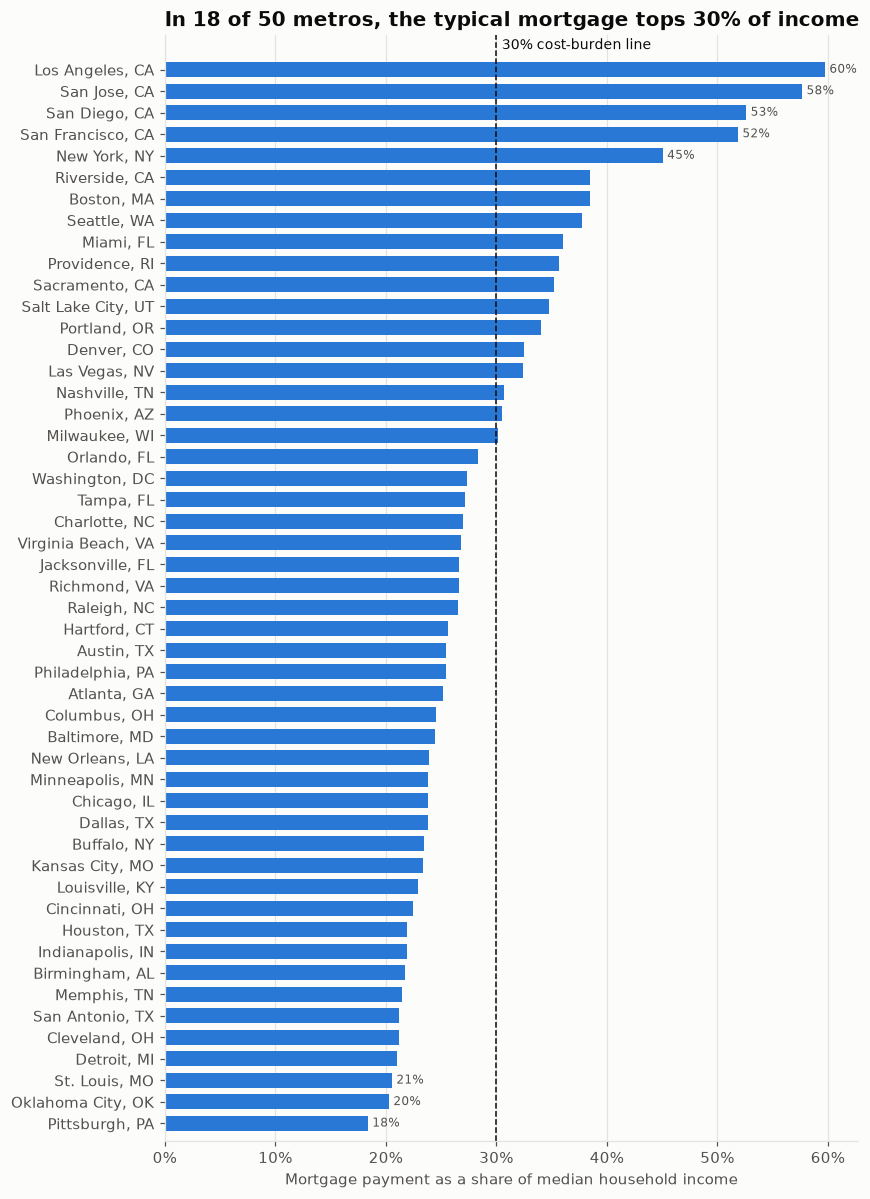

In [2]:
d = latest.sort_values("payment_to_income")
burdened = (d["payment_to_income"] > 0.30).sum()

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(d["metro"], d["payment_to_income"], color=BLUE, height=0.7)
ax.axvline(0.30, color=INK, linewidth=1, linestyle="--")
ax.text(0.305, len(d) - 0.2, "30% cost-burden line", color=INK, fontsize=9, va="bottom")
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.8, len(d) + 0.6)
ax.set_xlabel("Mortgage payment as a share of median household income")
ax.set_title(f"In {burdened} of {len(d)} metros, the typical mortgage tops 30% of income")
for y, v in enumerate(d["payment_to_income"]):
    if y >= len(d) - 5 or y < 3:
        ax.text(v + 0.004, y, f"{v:.0%}", va="center", fontsize=8, color=MUTED)
plt.tight_layout()

## 2. How much has it changed since 2021?

Home prices kept rising and mortgage rates roughly doubled, while incomes grew more slowly.

Median change: +9.2 percentage points
Largest increases: San Jose, CA (+20.4 pts), Los Angeles, CA (+20.2 pts), San Diego, CA (+18.9 pts), New York, NY (+14.8 pts), Boston, MA (+13.8 pts)


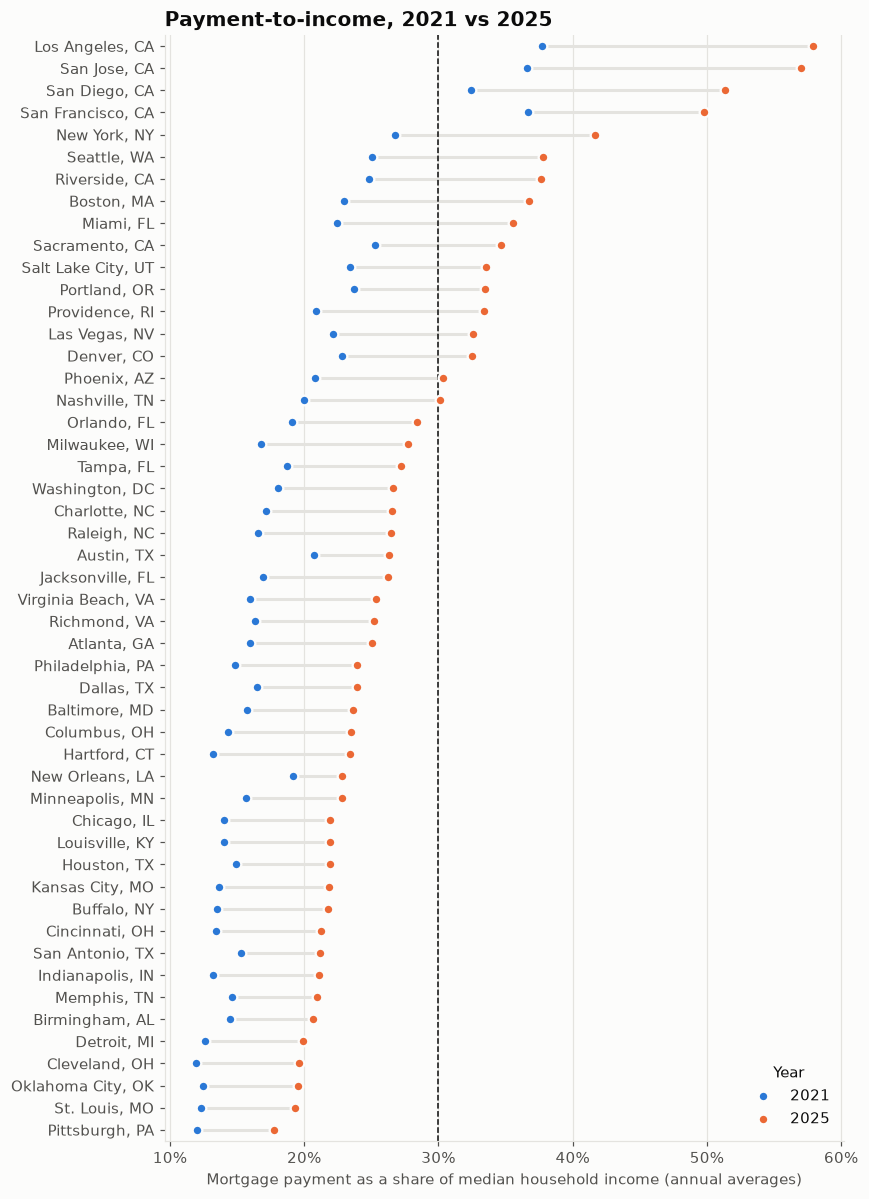

In [3]:
first, last = annual["year"].min(), annual["year"].max()
w = annual.pivot(index="metro", columns="year", values="payment_to_income")[[first, last]].sort_values(last)

fig, ax = plt.subplots(figsize=(8, 11))
y = range(len(w))
ax.hlines(y, w[first], w[last], color=GRID, linewidth=2, zorder=1)
ax.scatter(w[first], y, color=BLUE, s=40, zorder=2, label=str(first), edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(w[last], y, color=ORANGE, s=40, zorder=3, label=str(last), edgecolor="#fcfcfb", linewidth=1.5)
ax.set_yticks(list(y), w.index)
ax.axvline(0.30, color=INK, linewidth=1, linestyle="--")
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="y", visible=False)
ax.margins(y=0.01)
ax.legend(loc="lower right", frameon=False, title="Year")
ax.set_xlabel("Mortgage payment as a share of median household income (annual averages)")
ax.set_title(f"Payment-to-income, {first} vs {last}")
plt.tight_layout()

chg = (w[last] - w[first]).sort_values()
print(f"Median change: {chg.median()*100:+.1f} percentage points")
print("Largest increases:", ", ".join(f"{m} ({v*100:+.1f} pts)" for m, v in chg.tail(5)[::-1].items()))

## 3. Rent or buy?

Points above the diagonal are metros where the mortgage on a typical home costs more than renting one.

Buying costs more than renting in 39 of 50 metros


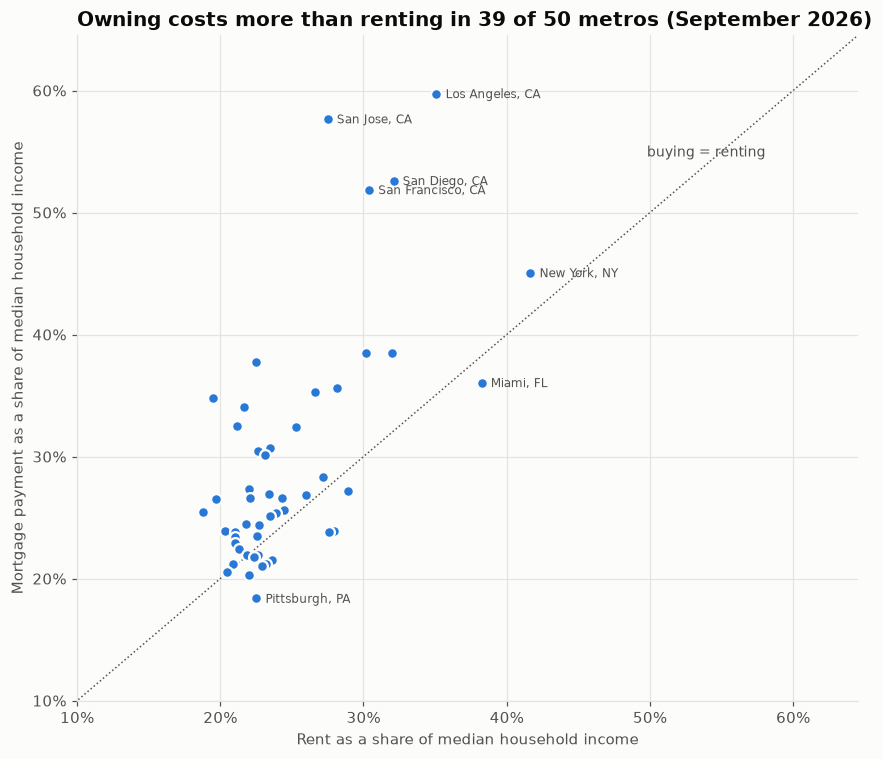

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(latest["rent_to_income"], latest["payment_to_income"], color=BLUE, s=50,
           edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
lim = max(latest["rent_to_income"].max(), latest["payment_to_income"].max()) * 1.08
ax.plot([0, lim], [0, lim], color=MUTED, linewidth=1, linestyle=":")
ax.text(lim * 0.9, lim * 0.86, "buying = renting", color=MUTED, fontsize=9, ha="right", va="top")
ax.set(xlim=(0.1, lim), ylim=(0.1, lim))
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Rent as a share of median household income")
ax.set_ylabel("Mortgage payment as a share of median household income")
gap = latest["payment_to_income"] - latest["rent_to_income"]
ax.set_title(f"Owning costs more than renting in {(gap > 0).sum()} of {len(gap)} metros ({as_of})")
for idx in dict.fromkeys([*gap.nlargest(4).index, *latest["rent_to_income"].nlargest(2).index, gap.idxmin()]):
    r = latest.loc[idx]
    ax.annotate(r["metro"], (r["rent_to_income"], r["payment_to_income"]), xytext=(6, -3),
                textcoords="offset points", fontsize=8, color=MUTED)
plt.tight_layout()
print(f"Buying costs more than renting in {(gap > 0).sum()} of {len(gap)} metros")

## 4. Home values since 2020

Indexed to January 2020 = 100, for a few contrasting metros.

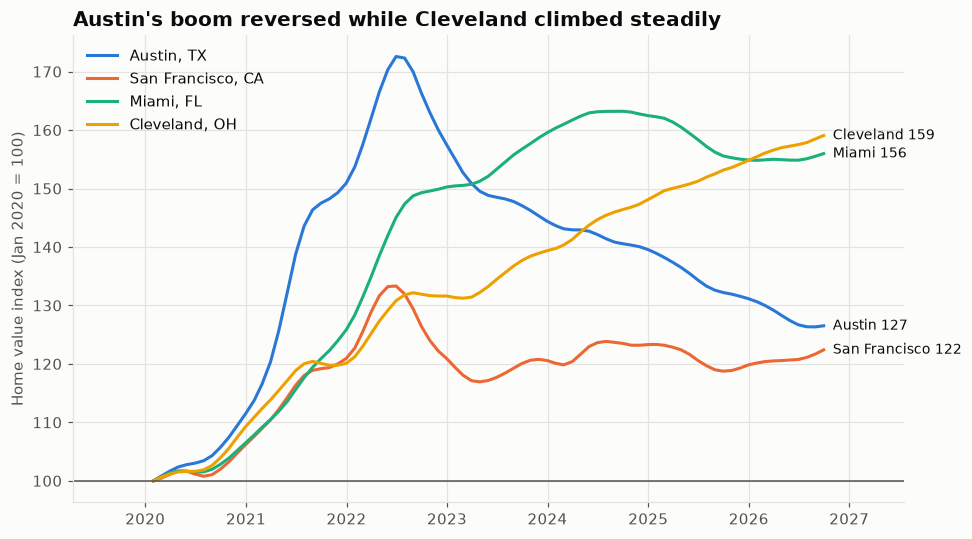

In [5]:
picks = {"Austin, TX": BLUE, "San Francisco, CA": ORANGE, "Miami, FL": AQUA, "Cleveland, OH": YELLOW}
m = monthly[monthly["metro"].isin(picks) & (monthly["date"] >= "2020-01-01")]

fig, ax = plt.subplots(figsize=(9, 5))
for metro, color in picks.items():
    s = m[m["metro"] == metro].set_index("date")["home_value"]
    s = s / s.iloc[0] * 100
    ax.plot(s.index, s, color=color, linewidth=2, label=metro)
    ax.annotate(f"{metro.split(',')[0]} {s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.axhline(100, color=MUTED, linewidth=1)
ax.legend(frameon=False, loc="upper left")
ax.set_ylabel("Home value index (Jan 2020 = 100)")
ax.set_title("Austin's boom reversed while Cleveland climbed steadily")
ax.margins(x=0.12)
plt.tight_layout()

## Full table

In [6]:
cols = ["metro", "home_value", "rent", "median_income", "price_to_income", "rent_to_income", "payment_to_income"]
(latest[cols].set_index("metro")
 .style.format({"home_value": "${:,.0f}", "rent": "${:,.0f}", "median_income": "${:,.0f}",
                "price_to_income": "{:.1f}", "rent_to_income": "{:.0%}", "payment_to_income": "{:.0%}"}))

,home_value,rent,median_income,price_to_income,rent_to_income,payment_to_income
metro,,,,,,
"Los Angeles, CA","$950,020","$2,929","$100,145",9.5,35%,60%
"San Jose, CA","$1,523,615","$3,812","$166,364",9.2,27%,58%
"San Diego, CA","$926,961","$2,967","$110,941",8.4,32%,53%
"San Francisco, CA","$1,120,379","$3,445","$136,020",8.2,30%,52%
"New York, NY","$730,949","$3,546","$102,139",7.2,42%,45%
"Riverside, CA","$580,321","$2,533","$94,933",6.1,32%,39%
"Boston, MA","$725,639","$2,987","$118,759",6.1,30%,38%
"Seattle, WA","$720,147","$2,250","$120,018",6.0,23%,38%
"Miami, FL","$476,815","$2,654","$83,261",5.7,38%,36%
